# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 5: PHÂN CỤM KHÁCH HÀNG MALL CUSTOMER SEGMENTATION BẰNG K-MEANS
### (KHẢO SÁT ĐẶC TRƯNG, ELBOW METHOD, SILHOUETTE SCORE, TRỰC QUAN HÓA 2D & 3D PLOTLY)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px
import plotly.graph_objects as go

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

print("Đã tải đầy đủ các thư viện cần thiết cho Bài 5.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã tải đầy đủ các thư viện cần thiết cho Bài 5.


### Câu 1: Nhập dữ liệu, thống kê các thông tin cơ bản, xử lý dữ liệu bị thiếu
Hướng dẫn: Sử dụng pandas để đọc file `Mall_Customers.csv`, kiểm tra thông tin bằng `info()`, `describe()`, in 5 mẫu đầu tiên và kiểm tra dữ liệu khuyết thiếu bằng `isnull().sum()`.

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

file_path = get_data_path("Dataset/Mall_Customers.csv")
df = pd.read_csv(file_path)

print("5 mẫu dữ liệu đầu tiên:")
display(df.head())

print("\nThông tin cấu trúc tập dữ liệu:")
df.info()

print("\nThống kê mô tả các thuộc tính định lượng:")
display(df.describe())

print("\nKiểm tra dữ liệu khuyết thiếu (Missing values):")
missing_values = df.isnull().sum()
print(missing_values)
print(f"Tổng số giá trị khuyết thiếu trong tập dữ liệu: {missing_values.sum()}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
5 mẫu dữ liệu đầu tiên:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Thông tin cấu trúc tập dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Thống kê mô tả các thuộc tính định lượng:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Kiểm tra dữ liệu khuyết thiếu (Missing values):
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Tổng số giá trị khuyết thiếu trong tập dữ liệu: 0


### Câu 2: Sử dụng biểu đồ tần suất (Histogram) biểu diễn phân phối của lần lượt các thuộc tính: Tuổi, Thu nhập hằng năm và Số điểm mua sắm
Hướng dẫn: Sử dụng matplotlib và seaborn để vẽ 3 biểu đồ Histogram có đường ước lượng mật độ (KDE) tương ứng cho 3 biến liên tục.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


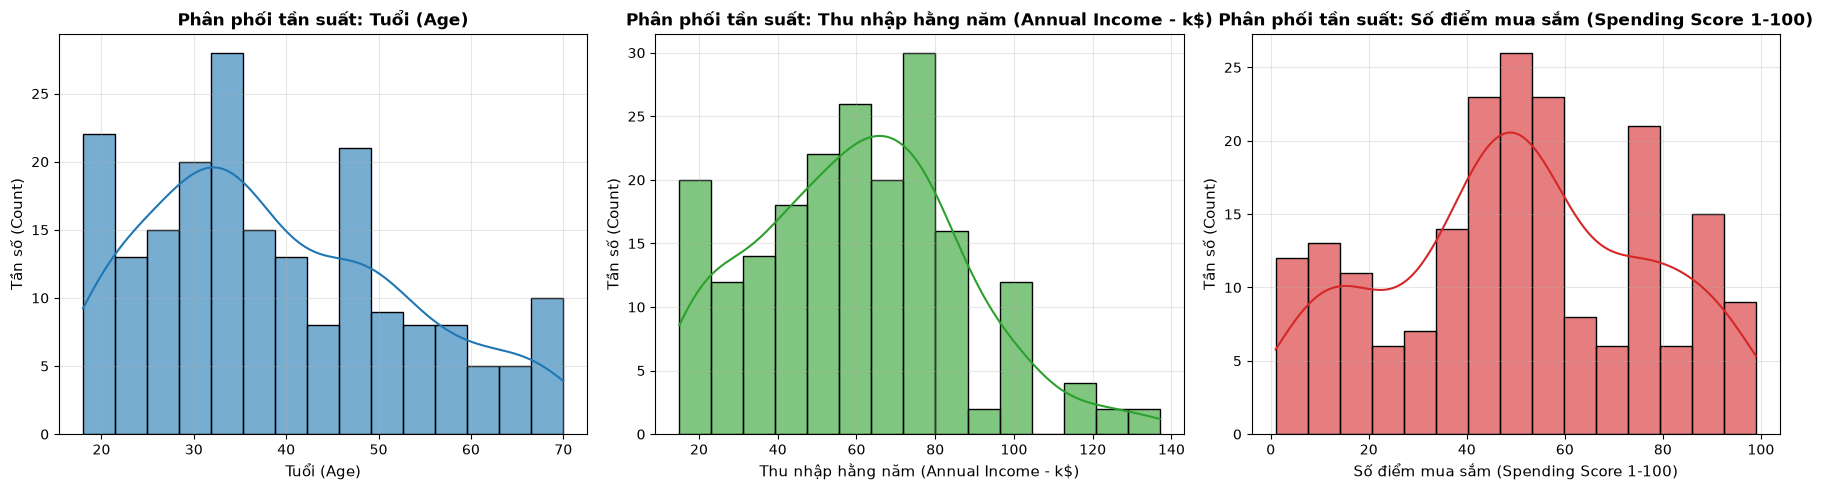

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
feature_names_vi = ['Tuổi (Age)', 'Thu nhập hằng năm (Annual Income - k$)', 'Số điểm mua sắm (Spending Score 1-100)']
colors = ['#1f77b4', '#2ca02c', '#d62728']

plt.figure(figsize=(18, 5))

for i, (col, col_name, color) in enumerate(zip(features, feature_names_vi, colors), 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=True, color=color, bins=15, edgecolor='black', alpha=0.6)
    plt.title(f'Phân phối tần suất: {col_name}', fontsize=12, fontweight='bold')
    plt.xlabel(col_name, fontsize=11)
    plt.ylabel('Tần số (Count)', fontsize=11)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Câu 3: Thống kê số mẫu dữ liệu theo thuộc tính Giới tính (Gender)
Hướng dẫn: Sử dụng biểu đồ đếm `sns.countplot` và thống kê tần suất xuất hiện của khách hàng Nam (Male) và Nữ (Female).

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Thống kê số lượng khách hàng theo giới tính:
  - Giới tính Female: 112 khách hàng (56.0%)
  - Giới tính Male: 88 khách hàng (44.0%)


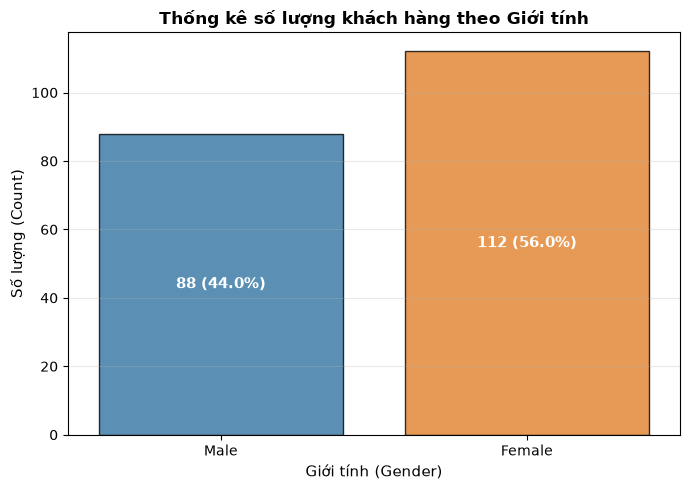

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

gender_counts = df['Gender'].value_counts()
print("Thống kê số lượng khách hàng theo giới tính:")
for gender, count in gender_counts.items():
    print(f"  - Giới tính {gender}: {count} khách hàng ({count / len(df) * 100:.1f}%)")

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Gender', palette=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.8)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.title('Thống kê số lượng khách hàng theo Giới tính', fontsize=12, fontweight='bold')
plt.xlabel('Giới tính (Gender)', fontsize=11)
plt.ylabel('Số lượng (Count)', fontsize=11)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Câu 4: Khảo sát phân bố của thuộc tính Tuổi (Age) và Thu nhập hằng năm (Annual Income) theo Giới tính
Hướng dẫn: Sử dụng biểu đồ phân tán (Scatter plot) với trục hoành là Tuổi, trục tung là Thu nhập hằng năm và phân biệt màu theo Giới tính.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


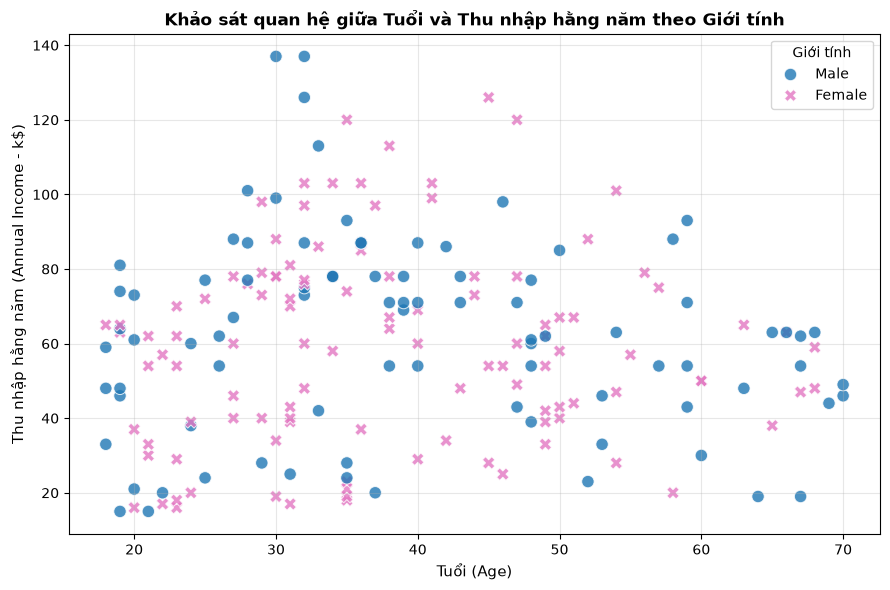

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    hue='Gender',
    style='Gender',
    s=80,
    alpha=0.8,
    palette={'Male': '#1f77b4', 'Female': '#e377c2'}
)
plt.title('Khảo sát quan hệ giữa Tuổi và Thu nhập hằng năm theo Giới tính', fontsize=12, fontweight='bold')
plt.xlabel('Tuổi (Age)', fontsize=11)
plt.ylabel('Thu nhập hằng năm (Annual Income - k$)', fontsize=11)
plt.legend(title='Giới tính', frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()